In [1]:
# 1. Import libraries
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

In [ ]:
df = pd.read_csv("/Users/atharva/Downloads/LP3/Patil/ML/dataset/2. sales_data_sample.csv", encoding="unicode_escape")

print(df.head())


   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye           NaN

In [6]:
# 3. Select numerical columns
X = df[['QUANTITYORDERED', 'SALES']]


In [7]:
# Remove missing values
X = X.dropna()

In [8]:
# 4. Feature scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [9]:
# 5. Elbow Method
wcss = []

for i in range(1, 11):
    model = KMeans(n_clusters=i, random_state=42, n_init=10)
    model.fit(X_scaled)
    wcss.append(model.inertia_)

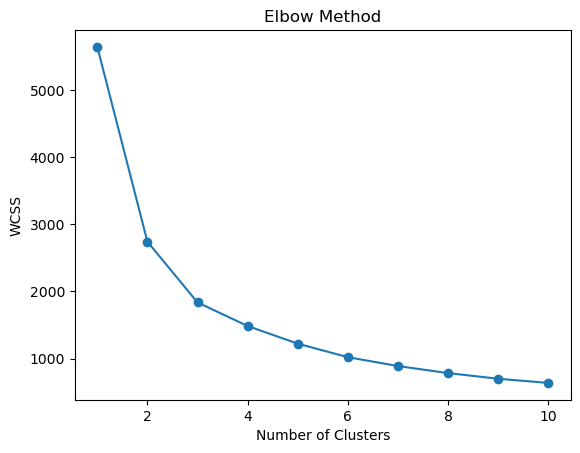

In [10]:
# Plot Elbow graph
plt.plot(range(1, 11), wcss, marker='o')
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.show()

In [11]:
# 6. Apply K-Means Clustering
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

df['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)

print("\nK-Means Clustering:")
print(df[['QUANTITYORDERED', 'SALES', 'KMeans_Cluster']].head())


K-Means Clustering:
   QUANTITYORDERED    SALES  KMeans_Cluster
0               30  2871.00               1
1               34  2765.90               2
2               41  3884.34               2
3               45  3746.70               2
4               49  5205.27               0


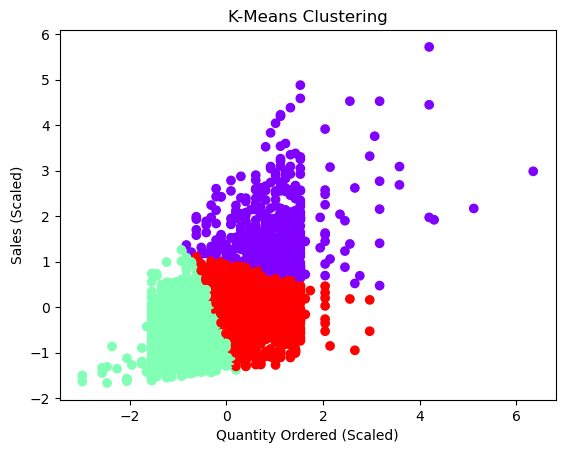

In [12]:
# 7. Visualize K-Means clusters
plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=df['KMeans_Cluster'],
    cmap='rainbow'
)
plt.title("K-Means Clustering")
plt.xlabel("Quantity Ordered (Scaled)")
plt.ylabel("Sales (Scaled)")
plt.show()

In [14]:
# 8. Hierarchical Clustering
hierarchical = AgglomerativeClustering(n_clusters=3)

df['Hierarchical_Cluster'] = hierarchical.fit_predict(X_scaled)

print("\nHierarchical Clustering:")
print(df[['QUANTITYORDERED', 'SALES', 'Hierarchical_Cluster']].head())


Hierarchical Clustering:
   QUANTITYORDERED    SALES  Hierarchical_Cluster
0               30  2871.00                     0
1               34  2765.90                     0
2               41  3884.34                     0
3               45  3746.70                     2
4               49  5205.27                     1


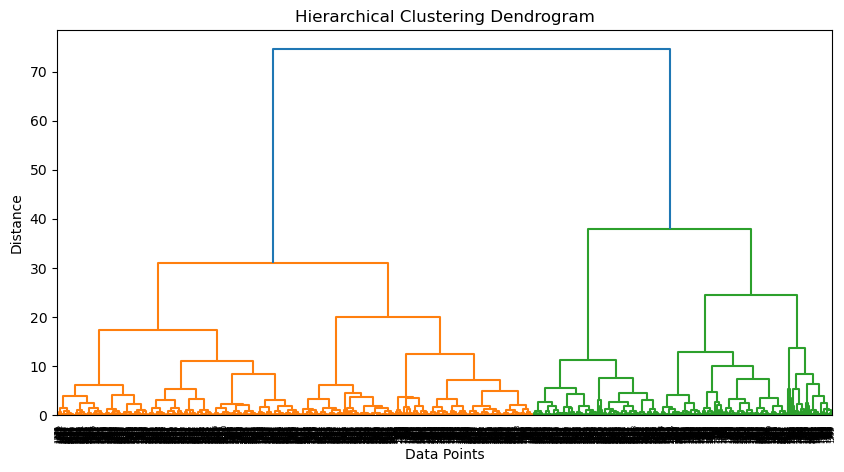

In [15]:
# 9. Dendrogram
linked = linkage(X_scaled, method='ward')

plt.figure(figsize=(10, 5))
dendrogram(linked)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Distance")
plt.show()